In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from astroquery.jplhorizons import Horizons
from astropy.time import Time

jd = Time('2007-02-28').jd          # converts the date to a Julian Date
obj = Horizons(id='599', location='500@10', epochs=jd)
v = obj.vectors()
print(v['targetname'][0])
print("Distance from Sun (AU):", float(np.sqrt(v['x']**2 + v['y']**2 + v['z']**2)[0]))

Jupiter (599)
Distance from Sun (AU): 5.349396601537589


In [2]:
import numpy as np, pandas as pd
from astroquery.jplhorizons import Horizons

AU  = 149597870.7   # km
DAY = 86400.0       # s

def get_vectors(target, center, start, stop, step='1h'):
    obj = Horizons(id=target, location=center,
                   epochs={'start': start, 'stop': stop, 'step': step})
    t = obj.vectors(refplane='ecliptic').to_pandas()
    df = pd.DataFrame({
        'jd':   t['datetime_jd'],
        'date': t['datetime_str'],
        'x':  t['x']*AU,  'y':  t['y']*AU,  'z':  t['z']*AU,          # km
        'vx': t['vx']*AU/DAY, 'vy': t['vy']*AU/DAY, 'vz': t['vz']*AU/DAY,  # km/s
    })
    df['r']     = np.sqrt(df.x**2 + df.y**2 + df.z**2)
    df['speed'] = np.sqrt(df.vx**2 + df.vy**2 + df.vz**2)
    return df

In [3]:
flybys = {
    'voyager2':     {'id': '-32', 'start': '1979-05-10', 'stop': '1979-09-07'},
    'newhorizons':  {'id': '-98', 'start': '2006-12-30', 'stop': '2007-04-29'},
}

frames = {'sun': '500@10', 'jup': '500@599'}

for name, f in flybys.items():
    for fname, center in frames.items():
        df = get_vectors(f['id'], center, f['start'], f['stop'])
        df.to_csv(f'data/{name}_{fname}.csv', index=False)
        print(f'{name}_{fname}: {len(df)} rows')

    # Jupiter around the Sun, same dates (for plots)
    jup = get_vectors('599', '500@10', f['start'], f['stop'])
    jup.to_csv(f'data/jupiter_{name}.csv', index=False)
    print(f'jupiter_{name}: {len(jup)} rows')

voyager2_sun: 2881 rows
voyager2_jup: 2881 rows
jupiter_voyager2: 2881 rows
newhorizons_sun: 2881 rows
newhorizons_jup: 2881 rows
jupiter_newhorizons: 2881 rows


In [4]:
for name in flybys:
    j = pd.read_csv(f'data/{name}_jup.csv')
    i = j['r'].idxmin()
    print(f"{name}: closest approach {j.loc[i,'date']}, "
          f"distance {j.loc[i,'r']:,.0f} km, speed {j.loc[i,'speed']:.1f} km/s")

voyager2: closest approach A.D. 1979-Jul-09 22:00:00.0000, distance 721,895 km, speed 20.2 km/s
newhorizons: closest approach A.D. 2007-Feb-28 06:00:00.0000, distance 2,304,577 km, speed 21.2 km/s


In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

AU = 149597870.7   # km
RJ = 71492.0       # Jupiter radius, km
names = {'voyager2': 'Voyager 2', 'newhorizons': 'New Horizons'}

data = {}
for n in names:
    data[n] = {'sun': pd.read_csv(f'data/{n}_sun.csv'),
               'jup': pd.read_csv(f'data/{n}_jup.csv'),
               'jupiter': pd.read_csv(f'data/jupiter_{n}.csv')}
    j = data[n]['jup']
    t0 = j.loc[j['r'].idxmin(), 'jd']          # time of closest approach
    for k in data[n]:
        data[n][k]['days'] = data[n][k]['jd'] - t0

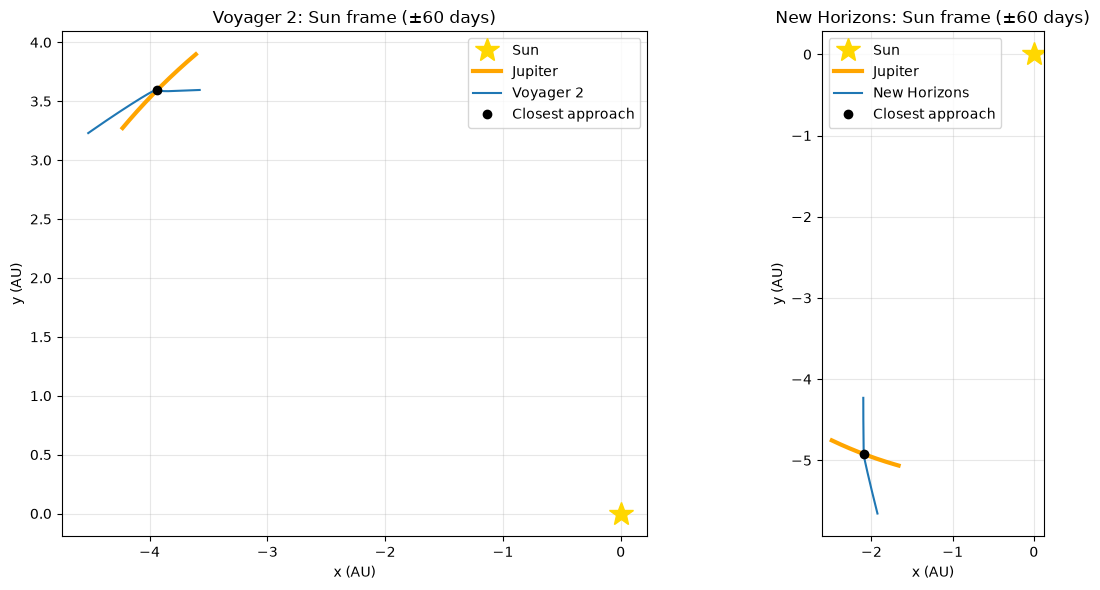

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (n, label) in zip(axes, names.items()):
    s, jp = data[n]['sun'], data[n]['jupiter']
    ax.plot(0, 0, '*', color='gold', ms=18, label='Sun')
    ax.plot(jp.x/AU, jp.y/AU, color='orange', lw=3, label='Jupiter')
    ax.plot(s.x/AU, s.y/AU, color='tab:blue', label=label)
    i = s['days'].abs().idxmin()
    ax.plot(s.x[i]/AU, s.y[i]/AU, 'ko', label='Closest approach')
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_xlabel('x (AU)'); ax.set_ylabel('y (AU)')
    ax.set_title(f'{label}: Sun frame (±60 days)'); ax.legend()
plt.tight_layout(); plt.savefig('plots/1_sun_frame.png', dpi=200); plt.show()

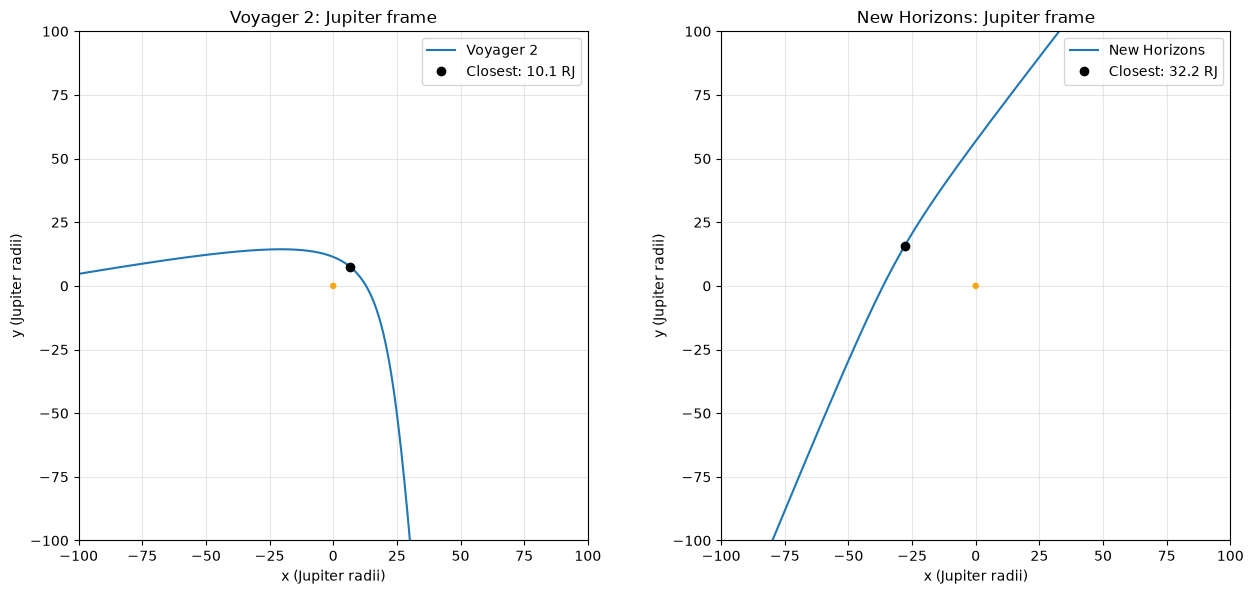

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (n, label) in zip(axes, names.items()):
    j = data[n]['jup']
    ax.add_patch(plt.Circle((0, 0), 1, color='orange'))   # Jupiter to scale
    ax.plot(j.x/RJ, j.y/RJ, color='tab:blue', label=label)
    i = j['r'].idxmin()
    ax.plot(j.x[i]/RJ, j.y[i]/RJ, 'ko', label=f"Closest: {j.r[i]/RJ:.1f} RJ")
    ax.set_xlim(-100, 100); ax.set_ylim(-100, 100)
    ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_xlabel('x (Jupiter radii)'); ax.set_ylabel('y (Jupiter radii)')
    ax.set_title(f'{label}: Jupiter frame'); ax.legend()
plt.tight_layout(); plt.savefig('plots/2_jupiter_frame.png', dpi=200); plt.show()

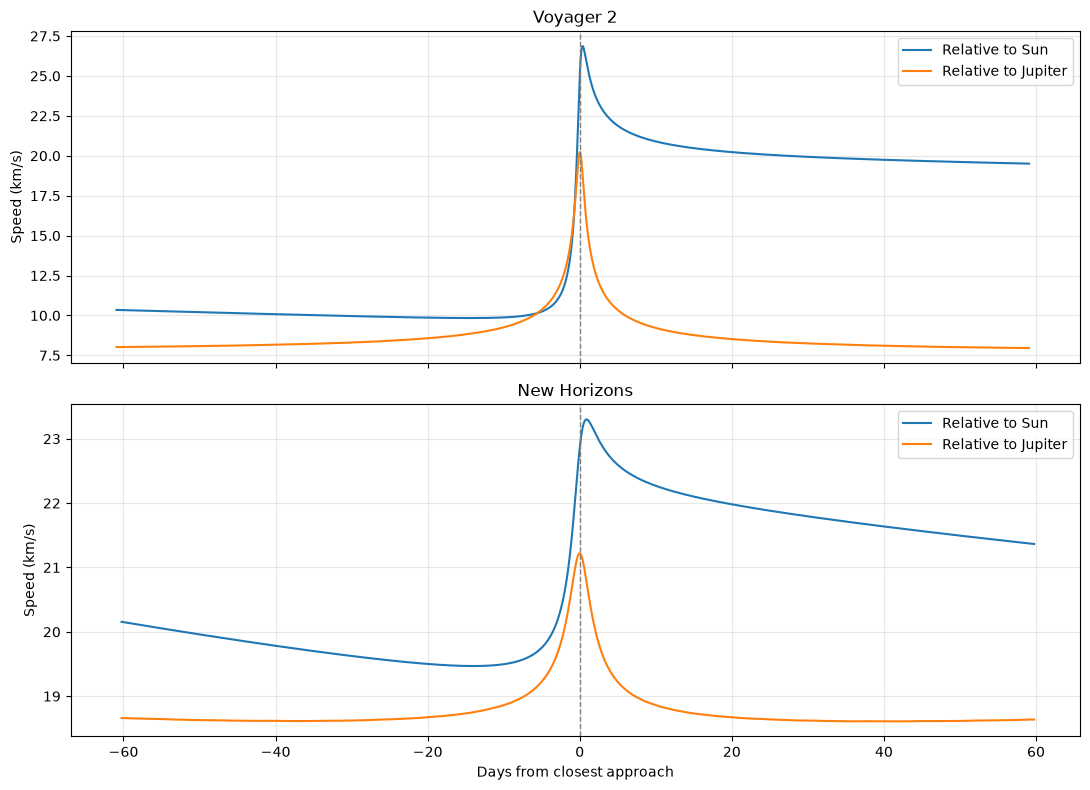

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ax, (n, label) in zip(axes, names.items()):
    ax.plot(data[n]['sun'].days, data[n]['sun'].speed, label='Relative to Sun')
    ax.plot(data[n]['jup'].days, data[n]['jup'].speed, label='Relative to Jupiter')
    ax.axvline(0, color='gray', ls='--', lw=1)
    ax.set_ylabel('Speed (km/s)'); ax.set_title(label)
    ax.grid(alpha=0.3); ax.legend()
axes[-1].set_xlabel('Days from closest approach')
plt.tight_layout(); plt.savefig('plots/3_speed_vs_time.png', dpi=200); plt.show()

In [9]:
MU_SUN = 1.32712440018e11   # km^3/s^2
MU_JUP = 1.26686534e8       # km^3/s^2

for n, label in names.items():
    j, jp = data[n]['jup'], data[n]['jupiter']
    r_soi = jp['r'].mean() * (MU_JUP/MU_SUN)**0.4
    print(f"{label}: SOI radius {r_soi/1e6:.0f} million km | "
          f"distance from Jupiter at -60 d: {j.r.iloc[0]/1e6:.0f}, "
          f"at +60 d: {j.r.iloc[-1]/1e6:.0f} million km")

Voyager 2: SOI radius 49 million km | distance from Jupiter at -60 d: 46, at +60 d: 44 million km
New Horizons: SOI radius 50 million km | distance from Jupiter at -60 d: 98, at +60 d: 97 million km


In [10]:
from scipy.integrate import solve_ivp

def sun_only(t, s):
    r = s[:3]
    return np.concatenate([s[3:], -MU_SUN * r / np.linalg.norm(r)**3])

results = {}
for n, label in names.items():
    s = data[n]['sun']
    b, a = s.iloc[0], s.iloc[-1]                     # before (-60 d), after (+60 d)
    r_b = b[['x','y','z']].to_numpy(float)
    v_b = b[['vx','vy','vz']].to_numpy(float)
    v_a = a[['vx','vy','vz']].to_numpy(float)

    T = (a.jd - b.jd) * 86400                        # seconds
    sol = solve_ivp(sun_only, [0, T], np.concatenate([r_b, v_b]),
                    method='DOP853', rtol=1e-11, atol=1e-6)
    v_nojup = sol.y[3:, -1]

    naive     = np.linalg.norm(v_a) - np.linalg.norm(v_b)
    corrected = np.linalg.norm(v_a) - np.linalg.norm(v_nojup)
    dv_vec    = np.linalg.norm(v_a - v_nojup)
    results[n] = {'naive': naive, 'speed_gain': corrected, 'dv_obs': dv_vec}

    print(f"{label}")
    print(f"  Speed before (-60 d):          {np.linalg.norm(v_b):6.2f} km/s")
    print(f"  Speed after  (+60 d):          {np.linalg.norm(v_a):6.2f} km/s")
    print(f"  No-Jupiter speed at +60 d:     {np.linalg.norm(v_nojup):6.2f} km/s")
    print(f"  Naive gain:                    {naive:6.2f} km/s")
    print(f"  Corrected speed gain:          {corrected:6.2f} km/s")
    print(f"  Velocity change |Δv| (vector): {dv_vec:6.2f} km/s\n")

Voyager 2
  Speed before (-60 d):           10.35 km/s
  Speed after  (+60 d):           19.51 km/s
  No-Jupiter speed at +60 d:       8.91 km/s
  Naive gain:                      9.16 km/s
  Corrected speed gain:           10.60 km/s
  Velocity change |Δv| (vector):  11.95 km/s

New Horizons
  Speed before (-60 d):           20.16 km/s
  Speed after  (+60 d):           21.36 km/s
  No-Jupiter speed at +60 d:      18.17 km/s
  Naive gain:                      1.21 km/s
  Corrected speed gain:            3.20 km/s
  Velocity change |Δv| (vector):   5.14 km/s



In [11]:
from astropy.time import Time

def vinf(row):
    return np.sqrt(row['speed']**2 - 2*MU_JUP/row['r'])

def angle_deg(a, b):
    return np.degrees(np.arccos(np.dot(a, b) / (np.linalg.norm(a)*np.linalg.norm(b))))

rows = {}
for n, label in names.items():
    j = data[n]['jup']

    # precise closest approach (1-minute data, ±2 hours)
    t_ca  = j.loc[j['r'].idxmin(), 'jd']
    start = Time(t_ca - 2/24, format='jd').strftime('%Y-%m-%d %H:%M')
    stop  = Time(t_ca + 2/24, format='jd').strftime('%Y-%m-%d %H:%M')
    sc_id = {'voyager2': '-32', 'newhorizons': '-98'}[n]
    fine  = get_vectors(sc_id, '500@599', start, stop, step='1m')
    r_p   = fine['r'].min()

    # v-infinity in and out
    first, last = j.iloc[0], j.iloc[-1]
    v_in, v_out = vinf(first), vinf(last)
    v_inf = (v_in + v_out) / 2

    # observed bend angle
    d_obs = angle_deg(first[['vx','vy','vz']].to_numpy(float),
                      last[['vx','vy','vz']].to_numpy(float))

    # theory
    s = 1 / (1 + r_p * v_inf**2 / MU_JUP)
    d_th  = 2 * np.degrees(np.arcsin(s))
    dv_th = 2 * v_inf * s
    dv_obs = results[n]['dv_obs']
    results[n].update({'v_inf': v_inf, 'r_p': r_p, 'dv_th': dv_th})

    rows[label] = {
        'v∞ in (km/s)': v_in, 'v∞ out (km/s)': v_out,
        'r_p (km)': r_p, 'r_p (RJ)': r_p/RJ,
        'Bend δ observed (°)': d_obs, 'Bend δ theory (°)': d_th,
        '|Δv| observed (km/s)': dv_obs, '|Δv| theory (km/s)': dv_th,
        'Difference (%)': 100*(dv_obs - dv_th)/dv_th,
    }

table = pd.DataFrame(rows)
table.to_csv('data/theory_vs_observed.csv')
table.round(2)

,Voyager 2,New Horizons
v∞ in (km/s),7.67,18.59
v∞ out (km/s),7.59,18.57
r_p (km),721375.48,2304504.78
r_p (RJ),10.09,32.23
Bend δ observed (°),96.82,15.88
Bend δ theory (°),97.37,15.79
|Δv| observed (km/s),11.95,5.14
|Δv| theory (km/s),11.46,5.10
Difference (%),4.28,0.63


In [12]:
G0 = 9.80665
mass = {'voyager2': 722, 'newhorizons': 478}   # spacecraft launch mass, kg
isps = [220, 320, 450]

rows = []
for n, label in names.items():
    for dv_name, dv in [('Speed gain', results[n]['speed_gain']),
                        ('|Δv| vector', results[n]['dv_obs'])]:
        for isp in isps:
            ve = isp * G0 / 1000                        # km/s
            ratio = np.exp(dv / ve)                     # m0 / mf
            fuel = mass[n] * (ratio - 1)
            rows.append({'Spacecraft': label, 'Δv type': dv_name,
                         'Δv (km/s)': round(dv, 2), 'Isp (s)': isp,
                         'Mass ratio m0/mf': round(ratio, 1),
                         'Fuel fraction (%)': round(100*(1 - 1/ratio), 1),
                         'Fuel needed (kg)': round(fuel)})

fuel_table = pd.DataFrame(rows)
fuel_table.to_csv('data/fuel_estimate.csv', index=False)
fuel_table

,Spacecraft,Δv type,Δv (km/s),Isp (s),Mass ratio m0/mf,Fuel fraction (%),Fuel needed (kg)
0,Voyager 2,Speed gain,10.60,220,135.9,99.3,97406
1,Voyager 2,Speed gain,10.60,320,29.3,96.6,20420
2,Voyager 2,Speed gain,10.60,450,11.0,90.9,7248
3,Voyager 2,|Δv| vector,11.95,220,254.5,99.6,183009
4,Voyager 2,|Δv| vector,11.95,320,45.1,97.8,31818
5,Voyager 2,|Δv| vector,11.95,450,15.0,93.3,10108
6,New Horizons,Speed gain,3.20,220,4.4,77.3,1628
7,New Horizons,Speed gain,3.20,320,2.8,63.9,847
8,New Horizons,Speed gain,3.20,450,2.1,51.6,509
9,New Horizons,|Δv| vector,5.14,220,10.8,90.8,4693


v∞ = 7.6 km/s
  r_p =   2 RJ: bend simulated 139.70°, theory 139.70°, Δv = 14.27 km/s
  r_p =   5 RJ: bend simulated 118.59°, theory 118.60°, Δv = 13.07 km/s
  r_p =  10 RJ: bend simulated  97.90°, theory  97.91°, Δv = 11.46 km/s
  r_p =  20 RJ: bend simulated  74.49°, theory  74.51°, Δv =  9.20 km/s
  r_p =  40 RJ: bend simulated  51.42°, theory  51.45°, Δv =  6.59 km/s
  r_p =  80 RJ: bend simulated  32.14°, theory  32.19°, Δv =  4.21 km/s


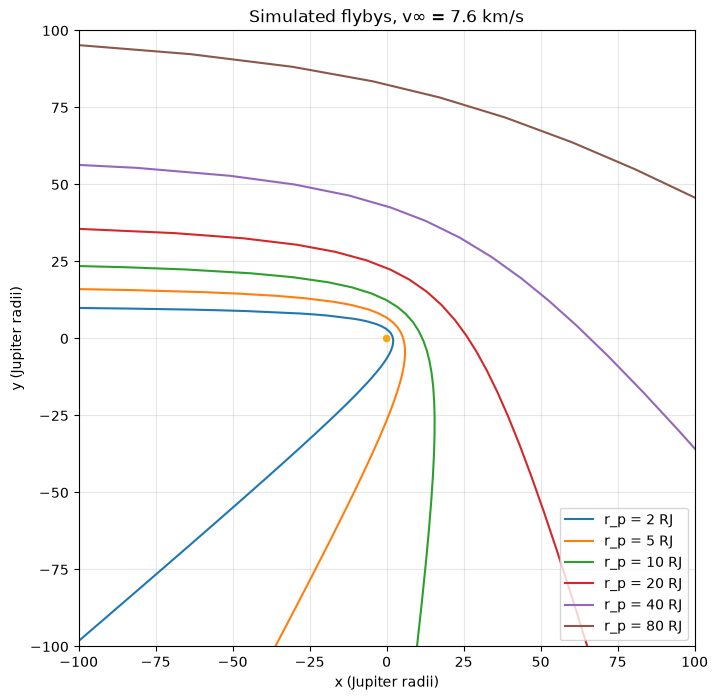

In [13]:
def jup_only(t, s):
    r = s[:2]
    return np.concatenate([s[2:], -MU_JUP * r / np.linalg.norm(r)**3])

def simulate(r_p, v_inf, R0=2000*RJ):
    b  = r_p * np.sqrt(1 + 2*MU_JUP/(r_p * v_inf**2))   # aiming distance
    v0 = np.sqrt(v_inf**2 + 2*MU_JUP/R0)                # speed at start
    y0 = b * v_inf / v0
    s0 = [-np.sqrt(R0**2 - y0**2), y0, v0, 0.0]

    leave = lambda t, s: np.hypot(s[0], s[1]) - R0
    leave.terminal, leave.direction = True, 1
    sol = solve_ivp(jup_only, [0, 10*R0/v_inf], s0, events=leave,
                    method='DOP853', rtol=1e-10, atol=1e-3)

    v_start, v_end = sol.y[2:, 0], sol.y[2:, -1]
    delta = angle_deg(v_start, v_end)
    dv = 2 * v_inf * np.sin(np.radians(delta)/2)
    return sol, delta, dv

v_test = 7.6                          # Voyager 2-like approach speed, km/s
fig, ax = plt.subplots(figsize=(8, 8))
ax.add_patch(plt.Circle((0, 0), 1, color='orange'))
print(f"v∞ = {v_test} km/s")
for rp_RJ in [2, 5, 10, 20, 40, 80]:
    sol, d, dv = simulate(rp_RJ*RJ, v_test)
    d_th = 2*np.degrees(np.arcsin(1/(1 + rp_RJ*RJ*v_test**2/MU_JUP)))
    ax.plot(sol.y[0]/RJ, sol.y[1]/RJ, label=f'r_p = {rp_RJ} RJ')
    print(f"  r_p = {rp_RJ:3d} RJ: bend simulated {d:6.2f}°, theory {d_th:6.2f}°, Δv = {dv:5.2f} km/s")
ax.set_xlim(-100, 100); ax.set_ylim(-100, 100); ax.set_aspect('equal')
ax.set_xlabel('x (Jupiter radii)'); ax.set_ylabel('y (Jupiter radii)')
ax.set_title(f'Simulated flybys, v∞ = {v_test} km/s'); ax.grid(alpha=0.3); ax.legend()
plt.savefig('plots/4_simulated_flybys.png', dpi=200); plt.show()

In [14]:
rows = []
for n, label in names.items():
    s = data[n]['sun']
    for D in [30, 45, 60]:
        b = s.loc[(s['days'] + D).abs().idxmin()]
        a = s.loc[(s['days'] - D).abs().idxmin()]
        r_b = b[['x','y','z']].to_numpy(float)
        v_b = b[['vx','vy','vz']].to_numpy(float)
        v_a = a[['vx','vy','vz']].to_numpy(float)
        T = (a.jd - b.jd) * 86400
        sol = solve_ivp(sun_only, [0, T], np.concatenate([r_b, v_b]),
                        method='DOP853', rtol=1e-11, atol=1e-6)
        v_nojup = sol.y[3:, -1]
        rows.append({'Spacecraft': label, 'Window (± days)': D,
                     'Speed gain (km/s)': np.linalg.norm(v_a) - np.linalg.norm(v_nojup),
                     '|Δv| observed (km/s)': np.linalg.norm(v_a - v_nojup)})

window = pd.DataFrame(rows).round(2)
window.to_csv('data/window_sensitivity.csv', index=False)
window

,Spacecraft,Window (± days),Speed gain (km/s),|Δv| observed (km/s)
0,Voyager 2,30,10.71,12.41
1,Voyager 2,45,10.62,12.12
2,Voyager 2,60,10.60,11.95
3,New Horizons,30,3.15,5.16
4,New Horizons,45,3.18,5.15
5,New Horizons,60,3.20,5.14


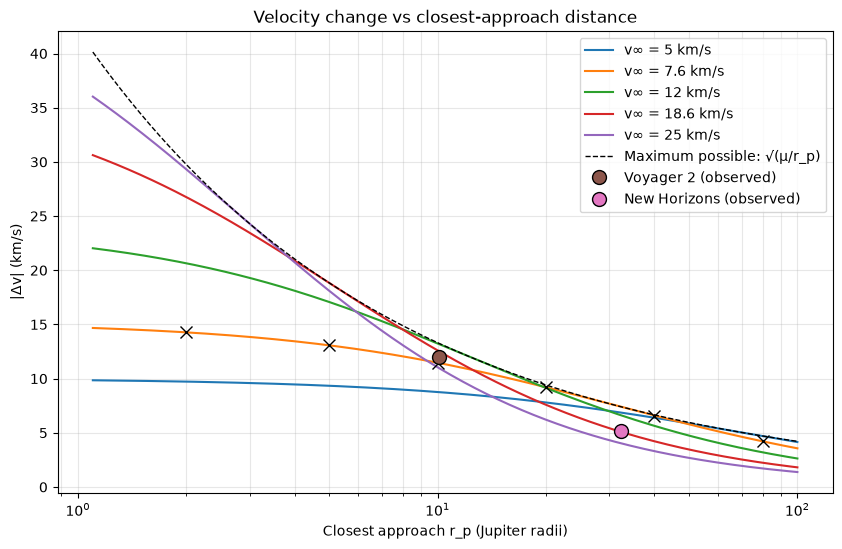

In [15]:
rp = np.logspace(np.log10(1.1), 2, 300) * RJ          # 1.1 to 100 RJ
fig, ax = plt.subplots(figsize=(10, 6))

for vi in [5, 7.6, 12, 18.6, 25]:
    dv = 2*vi / (1 + rp*vi**2/MU_JUP)
    ax.plot(rp/RJ, dv, label=f'v∞ = {vi} km/s')

# simulated points check the formula
for rp_RJ in [2, 5, 10, 20, 40, 80]:
    _, _, dv = simulate(rp_RJ*RJ, 7.6)
    ax.plot(rp_RJ, dv, 'kx', ms=8)

# maximum possible Δv at each distance
ax.plot(rp/RJ, np.sqrt(MU_JUP/rp), 'k--', lw=1, label='Maximum possible: √(μ/r_p)')

# the real spacecraft
for n, label in names.items():
    ax.plot(results[n]['r_p']/RJ, results[n]['dv_obs'], 'o', ms=10,
            mec='k', label=f'{label} (observed)')

ax.set_xscale('log'); ax.set_xlabel('Closest approach r_p (Jupiter radii)')
ax.set_ylabel('|Δv| (km/s)'); ax.grid(alpha=0.3, which='both')
ax.set_title('Velocity change vs closest-approach distance'); ax.legend()
plt.savefig('plots/5_dv_vs_rp.png', dpi=200); plt.show()